John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

### Import Packages

In [1]:
# Import packages
library(tidyverse)
options(repr.matrix.max.cols = Inf) # display all columns in tibbles

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


### Load and Trim Dataset

In [3]:
# minizord.csv already removed non-songs, post-dawn, unmeasureable songs, acoustic outliers
# see "Data Preprocessing/01 preprocessing.ipynb"
data <- read_csv("data/minizord.csv")

# Only look at North data for now
data <- data %>% filter(neighbourhood == "north") %>% ungroup()

Rows: 11694 Columns: 52
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (4): ID, IST, neighbourhood, Location_Number
dbl  (45): time_rel_sunrise, UST, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
lgl   (1): RepeatST
dttm  (1): DateTime
date  (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Reformat Data: Row for each possible matching opportunity of focal male

In [4]:
# Just focusing on one focal male for now (central male LbOW)
focal_id <- "LbOW"
focal_match_data <- data

In [5]:
ids <- c("LbOW", "RbDgY", "YKY", "TbTbLg", "DgTbO", "RRO") # Ordered list of IDs correstponding to M1..M6
for (i in 1:6) {
    print(ids[[i]])
    for (d in unique(na.omit(filter(data, ID==ids[[i]])$date))) {
        print(d)
        print(nrow(filter(data, ID == ids[[i]], date == d)))
    }
}

[1] "LbOW"
[1] 19125
[1] 80
[1] 19126
[1] 170
[1] 19128
[1] 5
[1] 19129
[1] 230
[1] 19130
[1] 224
[1] "RbDgY"
[1] 19128
[1] 214
[1] 19129
[1] 224
[1] 19130
[1] 221
[1] "YKY"
[1] 19125
[1] 172
[1] 19126
[1] 191
[1] 19128
[1] 259
[1] 19129
[1] 238
[1] 19130
[1] 212
[1] "TbTbLg"
[1] 19125
[1] 169
[1] 19126
[1] 169
[1] 19128
[1] 164
[1] 19129
[1] 112
[1] 19130
[1] 142
[1] "DgTbO"
[1] 19125
[1] 202
[1] 19126
[1] 233
[1] 19128
[1] 241
[1] 19129
[1] 260
[1] 19130
[1] 233
[1] "RRO"
[1] 19125
[1] 65
[1] 19126
[1] 158
[1] 19128
[1] 136
[1] 19129
[1] 125
[1] 19130
[1] 54


In [6]:
print(unique(na.omit(data$ID)))

[1] "DgTbO"  "LbOW"   "RRO"    "RbDgY"  "TbTbLg" "YKY"   


In [7]:
# Make column for time since Male N's last song
# NA values at top of each day until that male sings
ids <- c("LbOW", "RbDgY", "YKY", "TbTbLg", "DgTbO", "RRO") # Ordered list of IDs correstponding to M1..M6
for (i in 1:6) {
    print(ids[[i]])
    time_last_song <- sprintf("time_M%i_last_song", i)
    time_since_last_song <- sprintf("time_since_M%i_last_song", i)
    print(time_last_song)
    focal_match_data <- focal_match_data %>%
    arrange(DateTime) %>%
    mutate("{time_last_song}" := if_else(ID == ids[[i]], time_rel_sunrise, NA)) %>%
    group_by(date) %>%
    fill({time_last_song}, .direction = "down") %>%
    mutate("{time_since_last_song}" := time_rel_sunrise - !!sym({time_last_song})) %>%
    ungroup()
}

[1] "LbOW"
[1] "time_M1_last_song"
[1] "RbDgY"
[1] "time_M2_last_song"
[1] "YKY"
[1] "time_M3_last_song"
[1] "TbTbLg"
[1] "time_M4_last_song"
[1] "DgTbO"
[1] "time_M5_last_song"
[1] "RRO"
[1] "time_M6_last_song"


In [8]:
# Male i's nth last song
N_MAX <- 3
for (n in 1:N_MAX) {
        for (i in 1:6) {
                n_last_song <- sprintf("M%i_%i_last_UST", i, n)
                time_last_song <- sprintf("time_M%i_%i_last_song", i, n)
                time_since_last_song <- sprintf("time_since_M%i_%i_last_song", i, n)
                focal_match_data <- focal_match_data %>%
                # Sort by ID and DateTime
                        group_by(ID) %>%
                        arrange(DateTime) %>%
                # Take the Nth last UST, set it to MX_Nth_last_UST
                        mutate("{n_last_song}" := if_else(ID == ids[[i]], lag(UST, n-1), NA)) %>%
                        # mutate("{time_last_song}" := if_else(ID == ids[[i]], time_rel_sunrise, NA)) %>%
                        mutate("{time_last_song}" := if_else(ID == ids[[i]], lag(time_rel_sunrise, n-1), NA)) %>%
                        ungroup() %>% 
                # Sort by DateTime, forward fill
                        group_by(date) %>%
                        arrange(DateTime) %>%
                        fill({n_last_song}, .direction = "down") %>%
                        fill({time_last_song}, .direction = "down") %>%
                # Since we don't want the current song to count as the 1st last song, recalculate last songs for rows where ID matches MX
                        group_by(ID, date) %>%
                        arrange(DateTime) %>%
                        mutate("{n_last_song}" := if_else(ID == ids[[i]], lag(UST, n), !!sym({n_last_song}))) %>%
                        mutate("{time_last_song}" := if_else(ID == ids[[i]], lag(time_rel_sunrise, n), !!sym({time_last_song}))) %>%
                        ungroup() %>% 
                # Calculate time since Nth last song
                        group_by(date) %>%
                        mutate("{time_since_last_song}" := time_rel_sunrise - !!sym({time_last_song})) %>%
                        ungroup()
        }
}

[1] 1


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


[1] 2


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 3 rows containing non-finite outside the scale range (`stat_bin()`)."


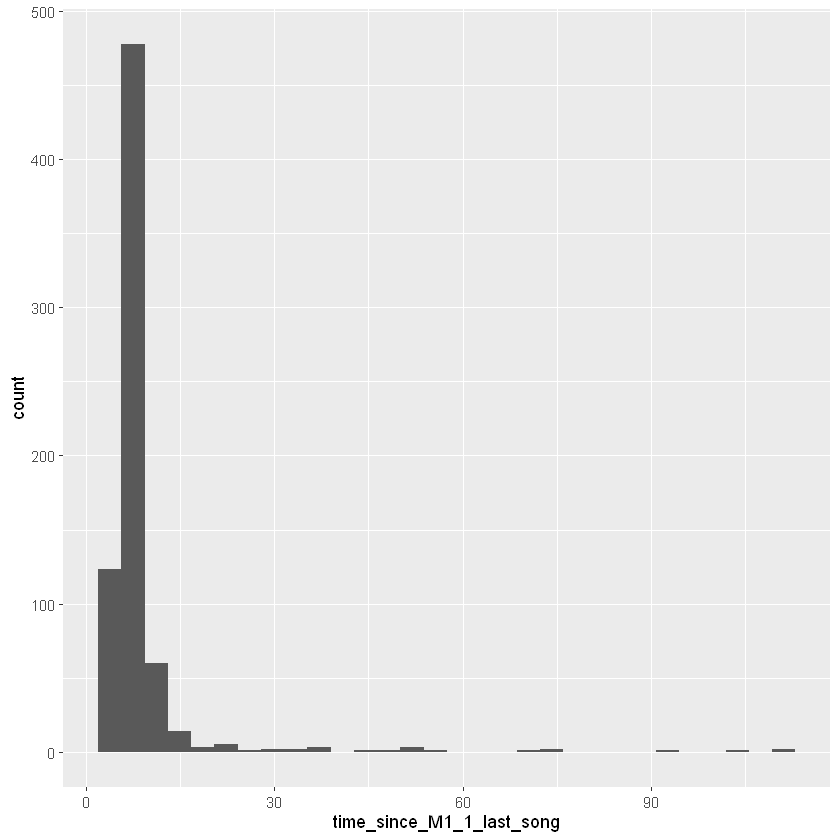

[1] 3


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


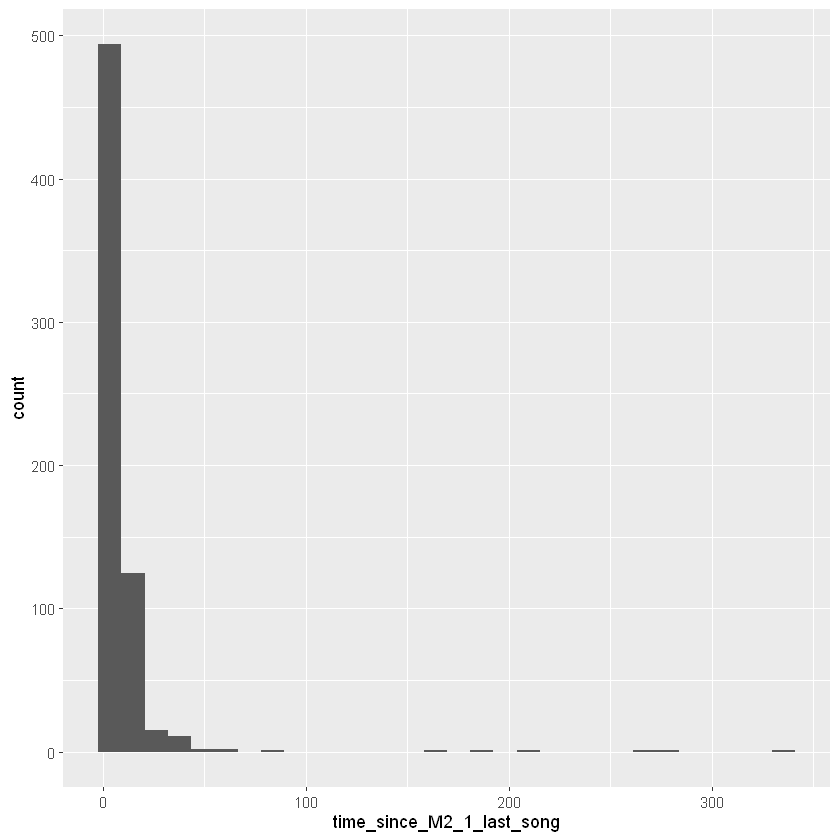

[1] 4


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


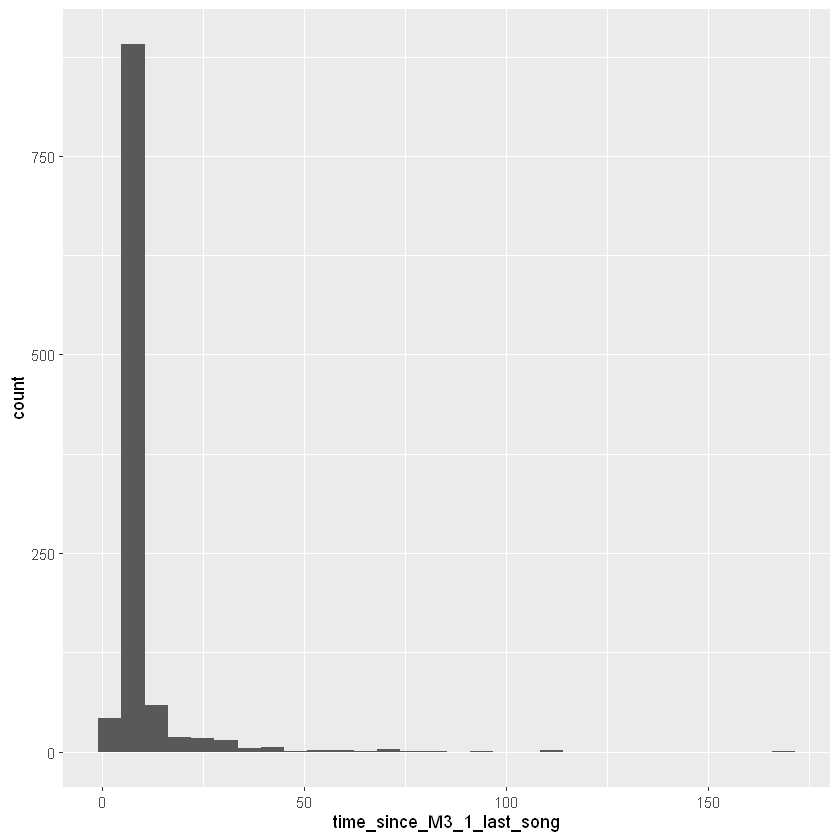

[1] 5


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


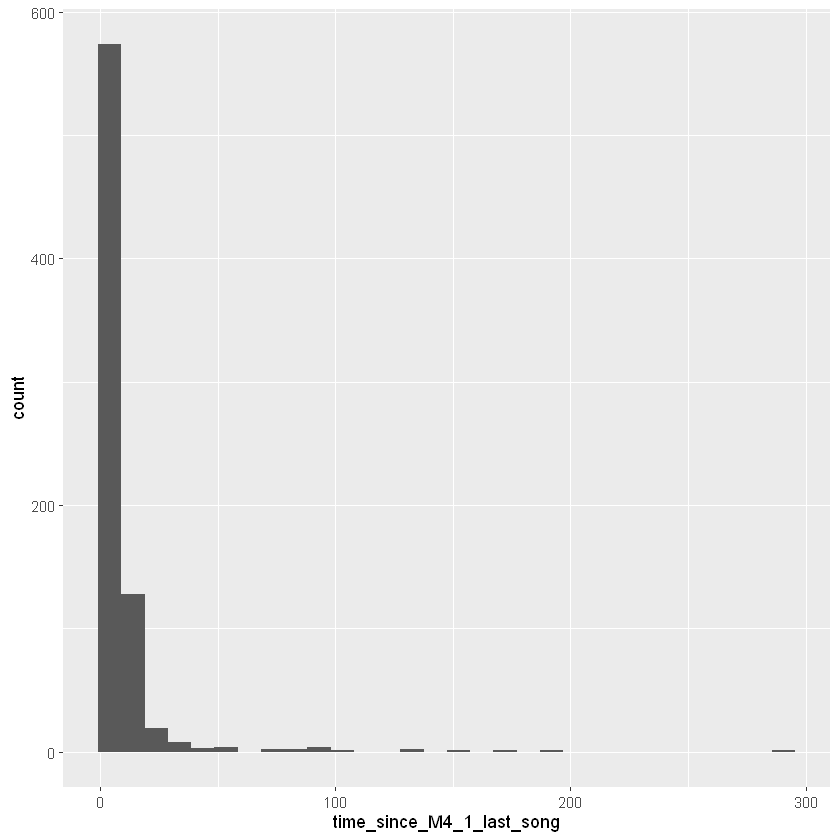

[1] 6


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


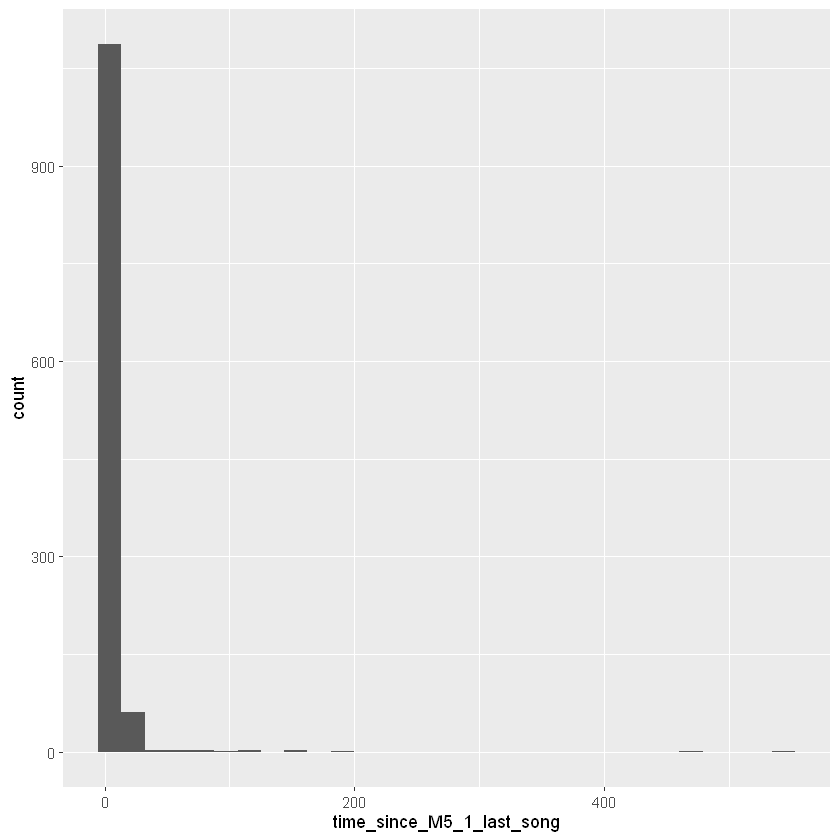

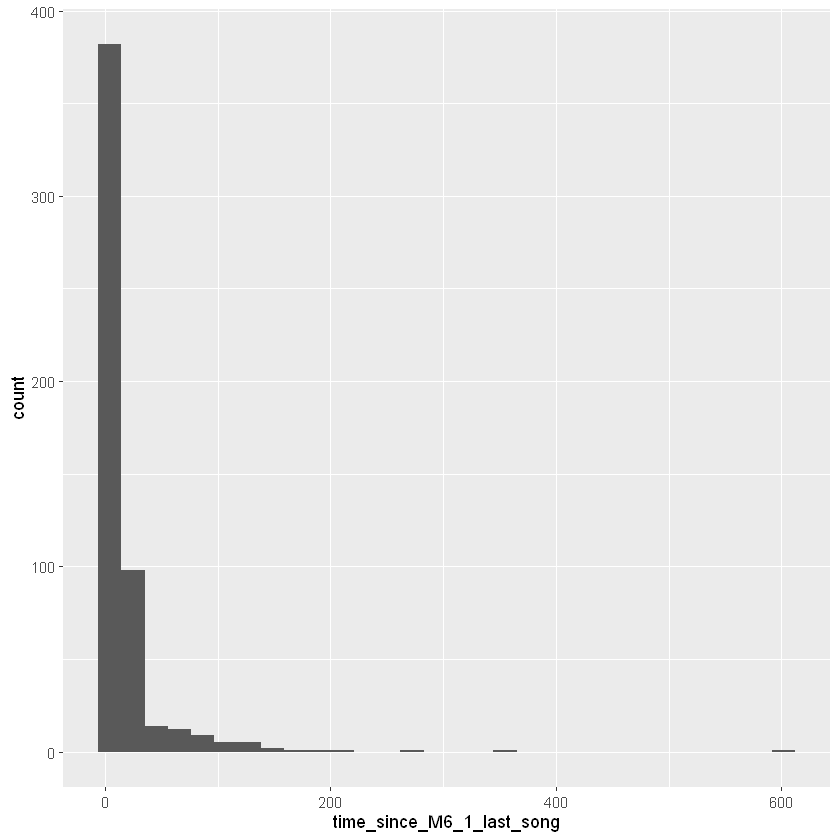

In [9]:
# How frequently do individuals typically sing?
for (i in 1:6) {
    print(i)
    plotting_data <- focal_match_data %>% 
        filter(ID == ids[[i]])
    plotting_column <- sprintf("time_since_M%i_1_last_song", i)
    plot <- ggplot(plotting_data) + 
        geom_histogram(aes(x=!!sym(plotting_column)))
    print(plot)
}

In [10]:
focal_match_data %>% select(contains("_1_last_song")) %>% select(contains("time_since")) %>% summary()
# focal_match_data %>% select(contains("_1_last_song")) %>% select(contains("time_since")) %>% quantile(probs=c(.1, .2, .3, .4, .5, .6, .7, .8, .9, 1), na.rm=TRUE)

 time_since_M1_1_last_song time_since_M2_1_last_song time_since_M3_1_last_song
 Min.   :  -0.9375         Min.   :  -0.9415         Min.   :8.908e-02        
 1st Qu.:   2.6249         1st Qu.:   2.5955         1st Qu.:2.653e+00        
 Median :   6.1049         Median :   5.3349         Median :5.445e+00        
 Mean   : 169.2045         Mean   :  11.5876         Mean   :1.452e+01        
 3rd Qu.:  56.5921         3rd Qu.:   7.3495         3rd Qu.:7.542e+00        
 Max.   :2428.2236         Max.   :1106.1609         Max.   :1.247e+03        
 NA's   :382               NA's   :1612              NA's   :140              
 time_since_M4_1_last_song time_since_M5_1_last_song time_since_M6_1_last_song
 Min.   :  -0.908          Min.   :  -0.9704         Min.   :  -0.9801        
 1st Qu.:   3.291          1st Qu.:   1.8129         1st Qu.:   4.7000        
 Median :   6.542          Median :   4.5395         Median :   9.2484        
 Mean   :  40.897          Mean   :  15.9008        

In [11]:
tail(focal_match_data)

ID,DateTime,date,time_rel_sunrise,UST,IST,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,D_M2_M3,D_M2_M4,D_M2_M5,D_M2_M6,D_M3_M4,D_M3_M5,D_M3_M6,D_M4_M5,D_M4_M6,D_M5_M6,M1_Lat,M1_Lon,M2_Lat,M2_Lon,M3_Lat,M3_Lon,M4_Lat,M4_Lon,M5_Lat,M5_Lon,M6_Lat,M6_Lon,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,M1_match,M2_match,M3_match,M4_match,M5_match,M6_match,number_of_matches,does_it_match,neighbourhood,Location_Number,Time_Diff,RepeatST,Repeat_ST_Run,time_M1_last_song,time_since_M1_last_song,time_M2_last_song,time_since_M2_last_song,time_M3_last_song,time_since_M3_last_song,time_M4_last_song,time_since_M4_last_song,time_M5_last_song,time_since_M5_last_song,time_M6_last_song,time_since_M6_last_song,M1_1_last_UST,time_M1_1_last_song,time_since_M1_1_last_song,M2_1_last_UST,time_M2_1_last_song,time_since_M2_1_last_song,M3_1_last_UST,time_M3_1_last_song,time_since_M3_1_last_song,M4_1_last_UST,time_M4_1_last_song,time_since_M4_1_last_song,M5_1_last_UST,time_M5_1_last_song,time_since_M5_1_last_song,M6_1_last_UST,time_M6_1_last_song,time_since_M6_1_last_song,M1_2_last_UST,time_M1_2_last_song,time_since_M1_2_last_song,M2_2_last_UST,time_M2_2_last_song,time_since_M2_2_last_song,M3_2_last_UST,time_M3_2_last_song,time_since_M3_2_last_song,M4_2_last_UST,time_M4_2_last_song,time_since_M4_2_last_song,M5_2_last_UST,time_M5_2_last_song,time_since_M5_2_last_song,M6_2_last_UST,time_M6_2_last_song,time_since_M6_2_last_song,M1_3_last_UST,time_M1_3_last_song,time_since_M1_3_last_song,M2_3_last_UST,time_M2_3_last_song,time_since_M2_3_last_song,M3_3_last_UST,time_M3_3_last_song,time_since_M3_3_last_song,M4_3_last_UST,time_M4_3_last_song,time_since_M4_3_last_song,M5_3_last_UST,time_M5_3_last_song,time_since_M5_3_last_song,M6_3_last_UST,time_M6_3_last_song,time_since_M6_3_last_song
<chr>,<dttm>,<date>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO,2022-05-18 05:49:27,2022-05-18,-332.39960,10,DgTbO_3,97.32587,39.73681,67.67739,60.4591,53.6376,60.45412,42.09414,151.8528,127.82773,43.97431,99.32688,69.72815,114.3889,111.6779,87.49532,17.98071,-67.1644,17.98140,-67.16383,17.98092,-67.16409,17.9813,-67.16421,17.98053,-67.16493,17.98029,-67.16415,12,19,166,62,10,10,0,0,0,0,0,1,1,1,north,Y.001,15,FALSE,1,-416.9097,84.51011,-350.85736,18.457761,-505.4082,173.0086,-487.5595,155.1599,-332.3996,0.00000,-1166.749,834.3490,12,-416.9097,84.51011,19,-350.8574,18.457761,166,-505.4082,173.0086,62,-487.5595,155.1599,8,-347.1553,14.75570,10,-1166.749,834.3490,12,-528.1699,195.7703,3,-516.1182,183.71863,3,-517.3018,184.9022,62,-517.2455,184.8459,8,-359.8293,27.42968,97,-1177.106,844.7061,3,-565.1429,232.7433,92,-526.4614,194.0618,9,-530.1072,197.7076,62,-527.9805,195.5809,8,-375.2745,42.87495,5,-1188.531,856.1316
RbDgY,2022-05-18 05:49:38,2022-05-18,-321.84534,8,RbDgY_2,94.03680,39.73681,67.67739,60.4591,53.6376,54.40540,62.24870,153.6539,110.10557,43.97431,99.32688,69.72815,114.3889,111.6779,87.49532,17.98071,-67.1644,17.98116,-67.16364,17.98092,-67.16409,17.9813,-67.16421,17.98053,-67.16493,17.98029,-67.16415,12,8,166,62,10,10,0,0,0,0,0,0,0,0,north,28,29,FALSE,1,-416.9097,95.06437,-321.84534,0.000000,-505.4082,183.5628,-487.5595,165.7142,-332.3996,10.55426,-1166.749,844.9033,12,-416.9097,95.06437,19,-350.8574,29.012023,166,-505.4082,183.5628,62,-487.5595,165.7142,10,-332.3996,10.55426,10,-1166.749,844.9033,12,-528.1699,20

In [12]:
# Focal Male's song-type repertoire
focal_repertoire <- unique(filter(data, ID == focal_id)$UST)
print("Focal Male's Song Type Repertoire:")
focal_repertoire

# Select only rows with focal male's songs
focal_match_data <- focal_match_data %>%
    filter(ID == focal_id) %>%
# Input variables: M1-M6's last UST, time since M1-M6 UST, # M2-M6's distance
    select(
        UST,
        DateTime, time_rel_sunrise,
        "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST",
        
        contains("last_UST"), # Nth last song
        contains("last_song"), # Time since last song
        # time_M1_last_song, time_M2_last_song, time_M3_last_song, time_M4_last_song, time_M5_last_song, time_M6_last_song,
    	time_since_M1_last_song, time_since_M2_last_song, time_since_M3_last_song, time_since_M4_last_song, time_since_M5_last_song, time_since_M6_last_song, # did not include time since M1 last song because it is always 0
        number_of_matches, does_it_match
        # Also consider adding "streak"
    ) %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
# Set all neighbours' songs that aren't in M1's repertoire to 0
    mutate(across(contains("UST"), ~ if_else (.x %in% focal_repertoire, .x, as.factor(0)))) %>%
# Also set NA song types to 0, for all Males except M1
    mutate(across(contains("UST"), ~ if_else (is.na(.x), as.factor(0), .x)))

[1] "Focal Male's Song Type Repertoire:"


[1]  10   3   8   9  13  29   5  16  21  NA  20 120  17 117 115 116 118 119  12

In [13]:
# If song sung more than X*n seconds ago, set to 0
x <- 15

for (n in 1:N_MAX) {
        for (i in 1:6) {
                n_last_song <- sprintf("M%i_%i_last_UST", i, n)
                time_since_last_song <- sprintf("time_since_M%i_%i_last_song", i, n)
                focal_match_data <- focal_match_data %>%
                mutate("{n_last_song}" := if_else(!!sym({time_since_last_song}) > x*n, as.factor(0), !!sym({n_last_song})))
        }
}

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 250 rows containing non-finite outside the scale range (`stat_bin()`)."


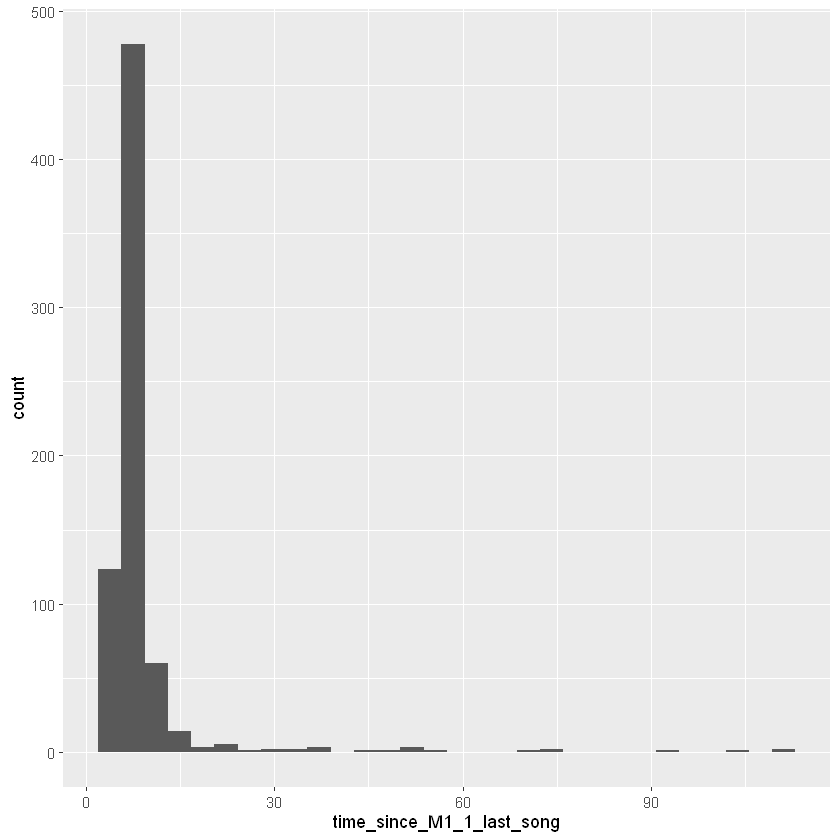

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 16 rows containing non-finite outside the scale range (`stat_bin()`)."


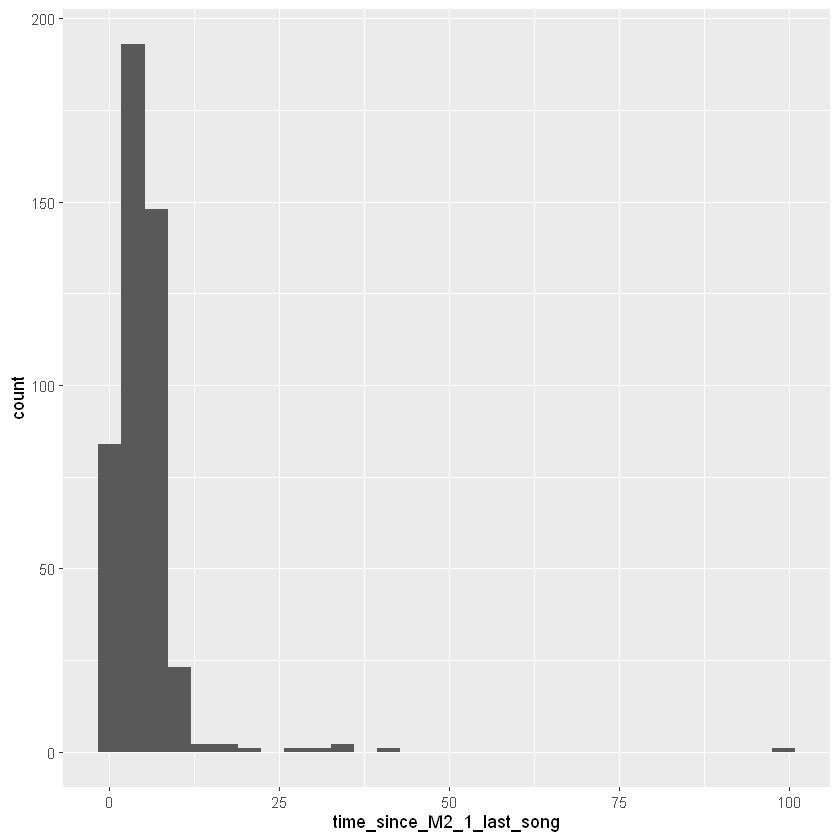

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 22 rows containing non-finite outside the scale range (`stat_bin()`)."


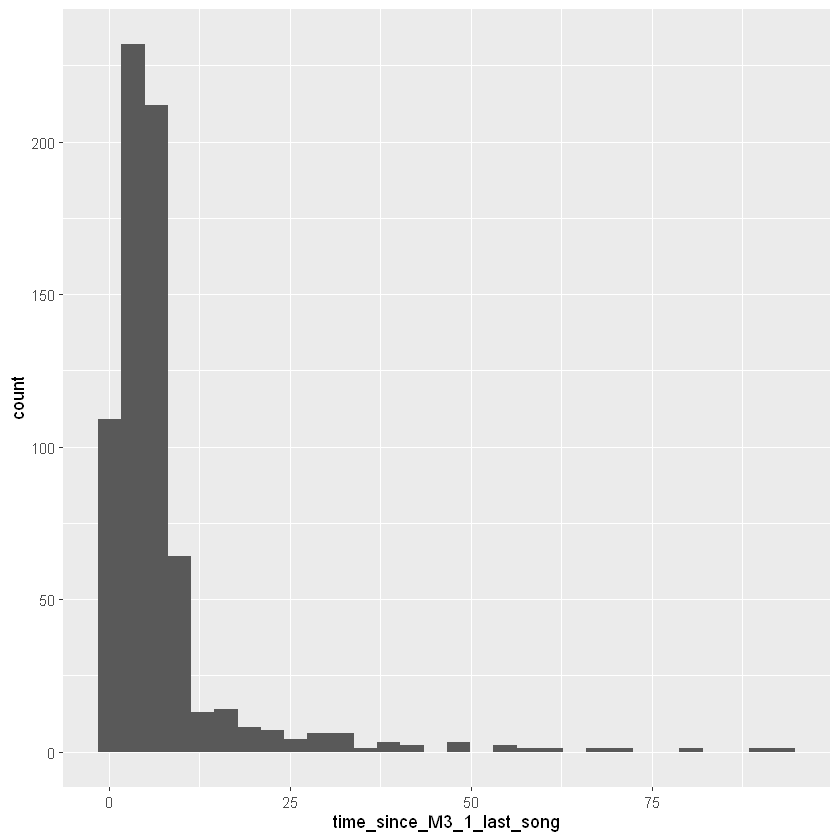

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 2 rows containing non-finite outside the scale range (`stat_bin()`)."


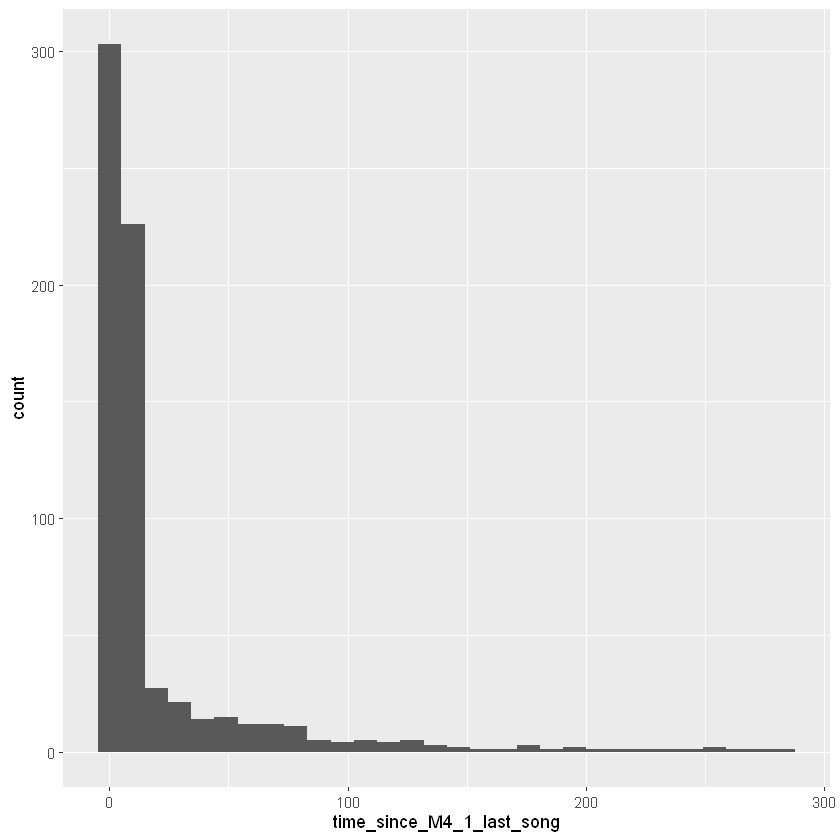

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 36 rows containing non-finite outside the scale range (`stat_bin()`)."


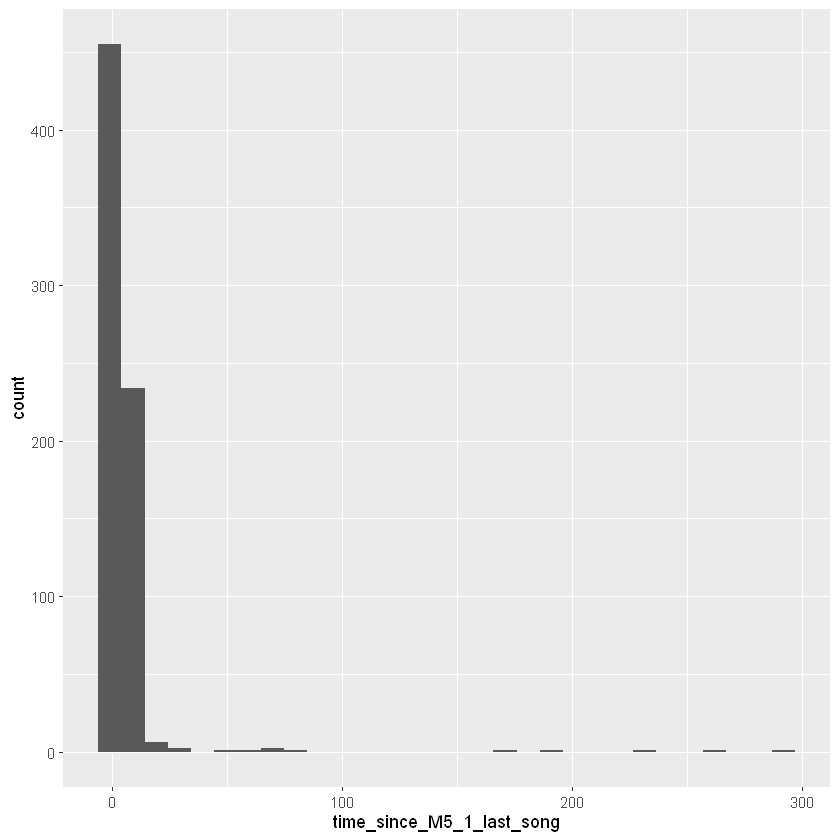

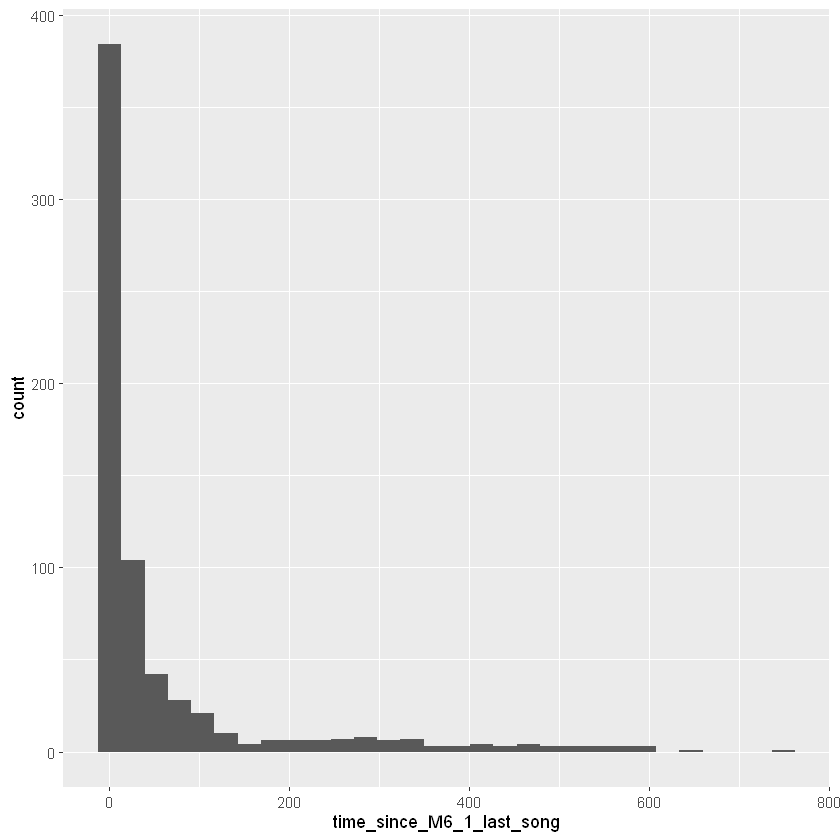

In [14]:
# How frequently do individuals typically sing?
for (i in 1:6) {
    plotting_column <- sprintf("time_since_M%i_1_last_song", i)
    plot <- ggplot(focal_match_data) + 
        geom_histogram(aes(x=!!sym(plotting_column)))
    print(plot)
}

In [15]:
# Compared to M1's repertoire, which songs are in the other males' repertoires?
# print("Male 1's Repertoire:")
# print(focal_repertoire)
for (i in 1:6) {
    print(sprintf("Male %i's Repertoire:", i))
    print(pull(unique(focal_match_data %>% select({sprintf("M%i_last_UST", i)}))))
    # print("\n")
}


[1] "Male 1's Repertoire:"
 [1] 10  3   8   9   13  29  5   16  21  20  0   120 17  117 115 116 118 119 12 
Levels: 0 3 5 8 9 10 12 13 16 17 20 21 29 115 116 117 118 119 120
[1] "Male 2's Repertoire:"
 [1] 0  8  9  3  21 13 5  16 20 17
Levels: 0 1 3 5 8 9 13 16 17 18 19 20 21 22 27 90 91 92
[1] "Male 3's Repertoire:"
 [1] 0  10 3  8  13 16 17 20 9  5  21
24 Levels: 0 1 3 5 8 9 10 13 16 17 18 19 20 21 22 27 30 35 165 166 167 ... 172
[1] "Male 4's Repertoire:"
 [1] 13 0  10 9  8  3  16 21 5  20 17
Levels: 0 1 3 5 8 9 10 13 16 17 18 19 20 21 22 60 61 62 64
[1] "Male 5's Repertoire:"
[1] 20 0  10 8  12
Levels: 0 1 4 6 7 8 10 11 12 15 20 25 32 33 153 154 155
[1] "Male 6's Repertoire:"
[1] 0  12 8  3  9  13 10 17 5 
Levels: 0 3 5 8 9 10 12 13 17 19 28 30 97 98


In [16]:
head(focal_match_data)

UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,M1_1_last_UST,M2_1_last_UST,M3_1_last_UST,M4_1_last_UST,M5_1_last_UST,M6_1_last_UST,M1_2_last_UST,M2_2_last_UST,M3_2_last_UST,M4_2_last_UST,M5_2_last_UST,M6_2_last_UST,M1_3_last_UST,M2_3_last_UST,M3_3_last_UST,M4_3_last_UST,M5_3_last_UST,M6_3_last_UST,time_M1_last_song,time_since_M1_last_song,time_M2_last_song,time_since_M2_last_song,time_M3_last_song,time_since_M3_last_song,time_M4_last_song,time_since_M4_last_song,time_M5_last_song,time_since_M5_last_song,time_M6_last_song,time_since_M6_last_song,time_M1_1_last_song,time_since_M1_1_last_song,time_M2_1_last_song,time_since_M2_1_last_song,time_M3_1_last_song,time_since_M3_1_last_song,time_M4_1_last_song,time_since_M4_1_last_song,time_M5_1_last_song,time_since_M5_1_last_song,time_M6_1_last_song,time_since_M6_1_last_song,time_M1_2_last_song,time_since_M1_2_last_song,time_M2_2_last_song,time_since_M2_2_last_song,time_M3_2_last_song,time_since_M3_2_last_song,time_M4_2_last_song,time_since_M4_2_last_song,time_M5_2_last_song,time_since_M5_2_last_song,time_M6_2_last_song,time_since_M6_2_last_song,time_M1_3_last_song,time_since_M1_3_last_song,time_M2_3_last_song,time_since_M2_3_last_song,time_M3_3_last_song,time_since_M3_3_last_song,time_M4_3_last_song,time_since_M4_3_last_song,time_M5_3_last_song,time_since_M5_3_last_song,time_M6_3_last_song,time_since_M6_3_last_song,number_of_matches,does_it_match
<fct>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<fct>
10,2022-05-13 05:37:08,-1161.593,NA,52.93973,67.67739,62.95599,53.6376,10,0,0,13,20,0,NA,NA,0,13,20,0,NA,NA,5,5,0,0,NA,NA,16,16,10,0,-1161.593,0,NA,NA,-1167.065,5.472131,-1167.219,5.626019,-1166.300,4.7073998,-1341.908,180.3157,NA,NA,NA,NA,-1167.065,5.472131,-1167.219,5.626019,-1166.300,4.7073998,-1341.908,180.3157,NA,NA,NA,NA,-1174.222,12.629357,-1176.024,14.431116,-1172.722,11.129006,-1355.29,193.6978,NA,NA,NA,NA,-1178.141,16.54797,-1182.597,21.00465,-1180.747,19.15384,-1386.335,224.7426,0,0
10,2022-05-13 05:37:21,-1148.784,NA,46.47336,67.67739,62.95599,53.6376,10,0,10,0,0,0,10,NA,10,0,0,0,NA,NA,13,10,0,0,NA,NA,21,13,0,0,-1148.784,0,NA,NA,-1149.934,1.149475,-1153.090,4.305930,-1148.543,-0.2417286,-1341.908,193.1240,-1161.593,12.808312,NA,NA,-1149.934,1.149475,-1153.090,4.305930,-1148.543,-0.2417286,-1341.908,193.1240,NA,NA,NA,NA,-1155.710,6.925988,-1160.260,11.475506,-1154.672,5.887165,-1355.29,206.5061,NA,NA,NA,NA,-1160.484,11.69908,-1167.219,18.43433,-1160.878,12.09377,-1386.335,237.5509,1,1
3,2022-05-13 05:37:29,-1140.450,NA,46.47336,67.67739,62.95599,53.6376,3,0,10,10,0,0,10,NA,10,10,0,0,10,NA,13,0,0,0,NA,NA,21,10,0,0,-1140.450,0,NA,NA,-1149.934,9.483614,-1148.608,8.158114,-1141.642,1.1915795,-1341.908,201.4581,-1148.784,8.334139,NA,NA,-1149.934,9.483614,-1148.608,8.158114,-1141.642,1.1915795,-1341.908,201.4581,-1161.593,21.14245,NA,NA,-1155.710,15.260127,-1153.090,12.640069,-1148.543,8.092410,-1355.29,214.8402,NA,NA,NA,NA,-1160.484,20.03322,-1160.260,19.80965,-1154.672,14.22130,-1386.335,245.8851,0,0
8,2022-05-13 05:37:39,-1130.582,NA,46.47336,67.67739,62.95599,53.6376,8,0,3,9,0,0,3,NA,3,9,0,0,10,NA,0,3,0,0,10,NA,10,10,0,0,-1130.582,0,NA,NA,-1132.836,2.253478,-1131.712,1.129353,-1136.170,5.5875481,-1341.908,211.3260,-1140.450,9.867840,NA,NA,-1132.836,2.253478,-1131.712,1.129353,-1136.170,5.5875481,-1341.908,211.3260,-1148.784,18.20198,NA,NA,-1140.324,9.741131,-1139.051,8.468500,-1141.642,11.059419,-1355.29,224.7080,-1161.593,31.01029,NA,NA,-1149.934,19.35145,-

### Export Data

In [18]:
write_csv(focal_match_data, "data/matching_opportunities.csv")